In [ ]:
import numpy as np
import matplotlib.pyplot as plt

**Teoria Geral**

$$\frac{d^2x}{dt^2} = -p(t)x' - q(t)x + g(x)$$

$$t_1 = x, t_1' = x' = t_2, t_2' = x'' = -p(t)t_2 - q(t)t_1 + g(x)$$

**Exercício Pêndulo**

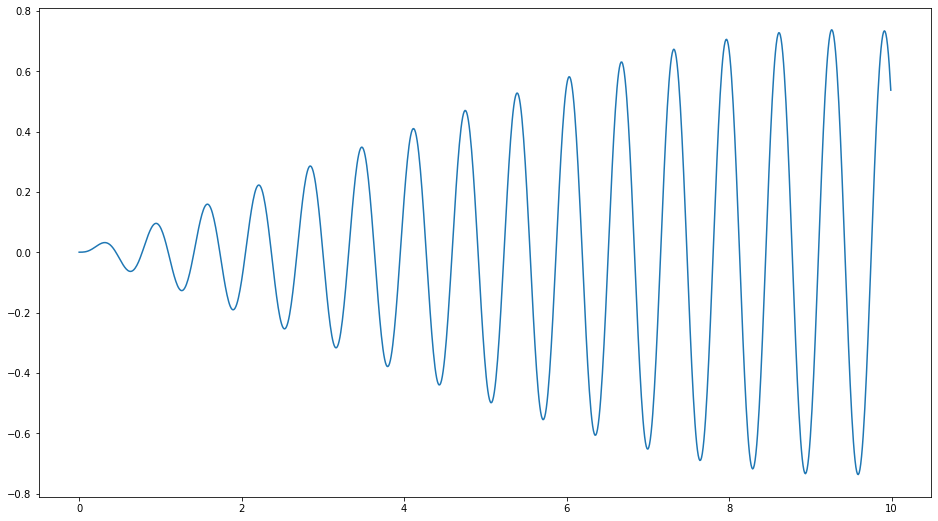

In [ ]:
def dPdT(r,t):
    f1 = r[1]
    f2 = -g/l * np.sin(r[0]) + C*np.cos(r[0])*np.sin(omega*t)
    return np.array([f1,f2], float)

def RungeKuttaMod(f, r_0, t_0, t, N):
    h = (t-t_0) / N
    t_p = np.arange(t_0, t, h)
    r_p = []
    for t in t_p:
        r_p.append(r_0[0])
        k1 = h*f(r_0,t)
        k2 = h*f(r_0+0.5*k1,t+0.5*h)
        k3 = h*f(r_0+0.5*k2,t+0.5*h)
        k4 = h*f(r_0+k3,t+h)
        r_0 += (k1+2*k2+2*k3+k4)/6
    return t_p,r_p

#Constantes
P_0 = [0,0]
t_0 = 0
t = 10
g = 9.81
l = 0.1
C = 2
omega = 5*2

t_p,r_p = RungeKuttaMod(dPdT, P_0, t_0, t, 1000)
plt.figure(figsize=(16,9))
plt.plot(t_p,r_p)

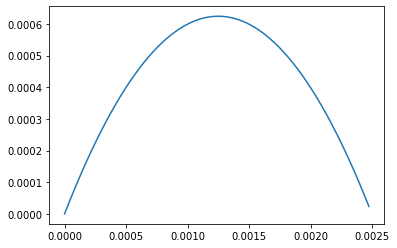

In [ ]:
def H(xi,t,a1):
    v = np.sqrt(xi[2]**2 + xi[3]**2)
    return np.array([xi[2],xi[3],-a1*xi[3]-xi[2]*v,-1+a1*xi[2]-xi[3]*v])

def trajectoria(phi,v0,T,M,a1):
    tempos = np.linspace(0,T,M+1)
    h = T/M
    xi = np.zeros([M+1,4])
    xi[0,:] = np.array([0,0,v0*np.cos(phi),v0*np.sin(phi)])
    for i in range(M):  
        k1 = h * H(xi[i,:],tempos[i],a1)
        k2 = h * H(xi[i,:] + k1/2, tempos[i] + h/2,a1)
        k3 = h * H(xi[i,:] + k2/2, tempos[i] + h/2,a1)
        k4 = h * H(xi[i,:] + k3, tempos[i] + h,a1)
        xi[i+1,:] =  xi[i,:] + (k1 + 2 * k2 + 2 * k3 + k4) / 6
    return tempos, xi

t,x = trajectoria(np.pi/4,0.05, 0.07,10000,0)
plt.plot(x[:,0],x[:,1])

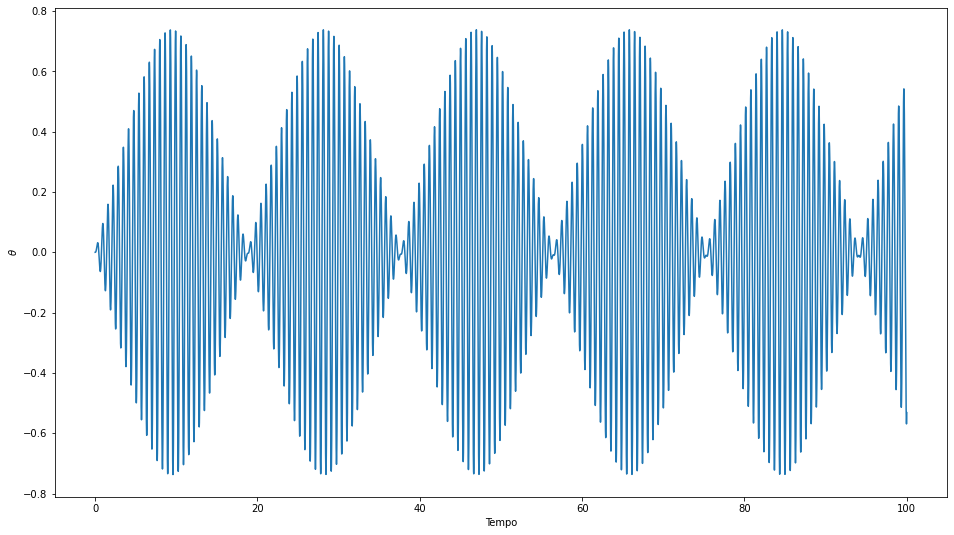

In [ ]:
def Pendulo(r, t, l, C, Omega):
    return np.array([r[1], -9.81/l * np.sin(r[0]) + C * np.cos(r[0]) * np.sin(Omega*t)])

def Runge(F, T, l, C, Omega, N):
    tempos = np.linspace(0, T, N)
    h = tempos[1] - tempos[0]
    r = np.zeros([N,2])
    r[0,:] = np.array([0, 0])
    for i in range(N-1):  
        k1 = h * F(r[i,:], tempos[i], l, C, Omega)
        k2 = h * F(r[i,:] + k1/2, tempos[i] + h/2, l, C, Omega)
        k3 = h * F(r[i,:] + k2/2, tempos[i] + h/2, l, C, Omega)
        k4 = h * F(r[i,:] + k3, tempos[i] + h, l, C, Omega)
        r[i+1,:] =  r[i,:] + (k1 + 2 * k2 + 2 * k3 + k4) / 6
    return tempos, r

tempos, r = Runge(Pendulo, 100, 0.1, 2, 10, 10000)
plt.figure(figsize = (16,9))
plt.ylabel(r'$\theta$')
plt.xlabel('Tempo')
plt.plot(tempos, r[:,0])
plt.show()